In [17]:
from ipynb.fs.full.model_train_test import df_train,df_test,predict,probab,actual,X_test,Y_test,model

In [18]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,classification_report


In [19]:
f1=f1_score(actual,predict)
acc=accuracy_score(actual,predict) #Ratio of total correct predictions to total predictions
confusion=confusion_matrix(actual,predict) #Table showing True Positives, True Negatives, False Positives, False Negatives
precision=precision_score(actual,predict) #Proportion of predicted positives that are actually positive
recall=recall_score(actual,predict) #Proportion of predicted positives from all the postitives that exist in the dataset

In [28]:
print(f"F1 score : {f1:.3f}")
print(f"Accuracy score : {acc:.3f}")
print(f"Confusion matrix : \n {confusion}")
print(f"Precision score : {precision:.3f}")
print(f"Recall score : {recall:.3f}")
print(f"True Positive : {confusion[0][0]}")
print(f"True Negative : {confusion[1][1]}")
print(f"False Positive : {confusion[0][1]}")
print(f"False Negative : {confusion[1][0]}")


F1 score : 0.851
Accuracy score : 0.872
Confusion matrix : 
 [[13140  1433]
 [ 1902  9501]]
Precision score : 0.869
Recall score : 0.833
True Positive : 13140
True Negative : 9501
False Positive : 1433
False Negative : 1902


## Classification Report

In [21]:
print(classification_report(actual, predict))

              precision    recall  f1-score   support

       False       0.87      0.90      0.89     14573
        True       0.87      0.83      0.85     11403

    accuracy                           0.87     25976
   macro avg       0.87      0.87      0.87     25976
weighted avg       0.87      0.87      0.87     25976



## Displaying the confusion matrix

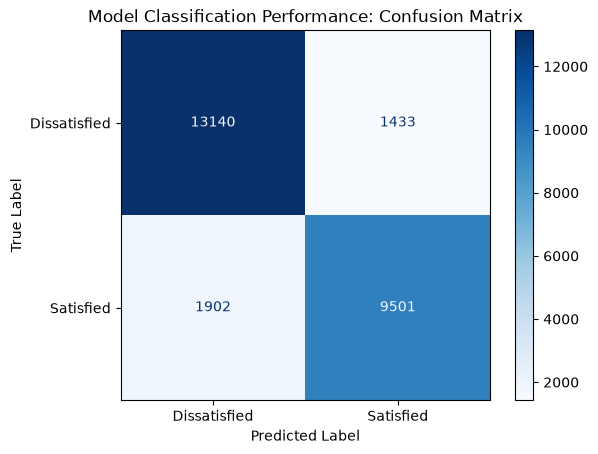

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=['Dissatisfied', 'Satisfied']) 

disp.plot(cmap=plt.cm.Blues, values_format='d')

plt.title("Model Classification Performance: Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## Analyzing Logistic Regression Feature Coefficients

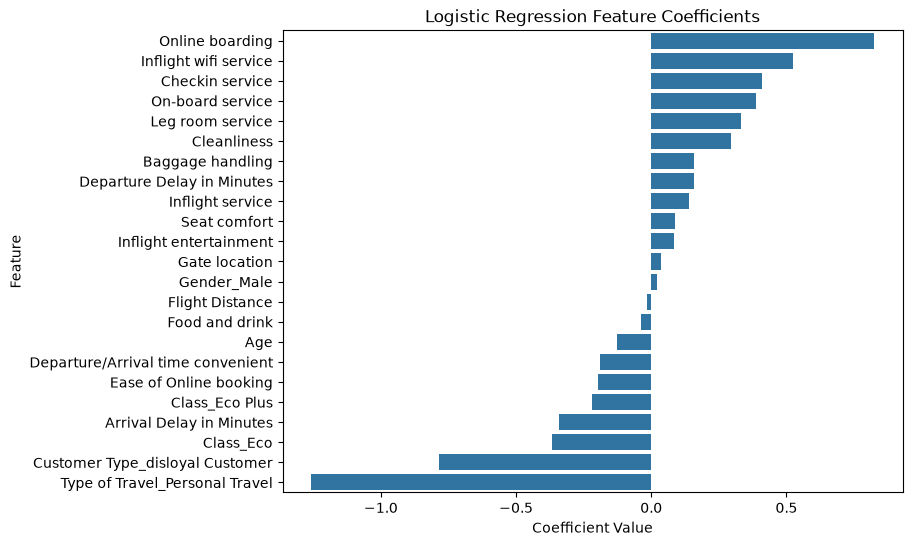

In [23]:
coefficients = pd.DataFrame({
    'Feature': X_test.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(x='Coefficient', y='Feature', data=coefficients)
plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.show()

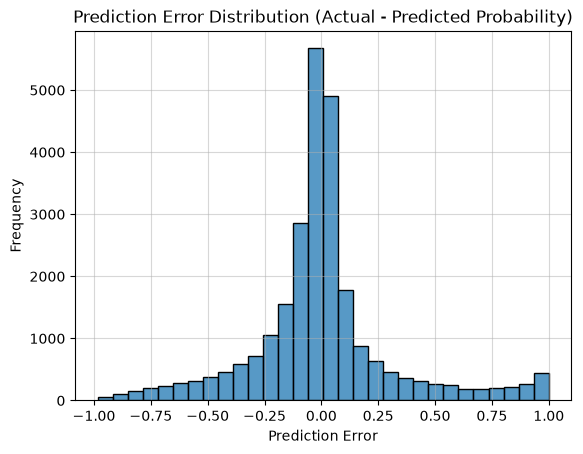

In [24]:
errors=np.array(Y_test)-np.array(probab)
sns.histplot(errors, bins=30)
plt.title('Prediction Error Distribution (Actual - Predicted Probability)')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.grid(alpha=0.5)
plt.show()